# Digital Image Processing Lab
**The University of Azad Jammu and Kashmir – Department of Software Engineering**


| **Name** | SAQLAIN MUSHTAQ |
|---|---|
| **Roll No.** | 2024-SE-35 |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Semester / Session** | Fifth / 2024-28 (SE) |
| **Lab Task** | # 04 – Geometric Transformations with Custom Inputs |

**Objective:** build one reusable `transform()` function that takes custom values, validates them, and produces correct geometric transformations (scale, crop, flip, translate, rotate).

**How the notebook is organised**

1. Load and validate the image
2. The reusable `transform()` function (with validation)
3. Interactive prompts (user selects the operation and types the parameters)
4. Demonstration of every operation
5. Interpolation comparison
6. Rejected (invalid) inputs
7. Identity checks (Pass / Fail table)
8. Concept notes and summary

## 0. Imports and settings

In [1]:
import os
import math
import hashlib
import tempfile
import textwrap

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams["figure.dpi"] = 60          # small figures -> small notebook file

# ---- settings -------------------------------------------------------------
INPUT_PATH = "input_image.jpg"           # the input image (kept next to the notebook)
OUTPUT_DIR = "outputs"                   # transformed images are saved here
JPEG_QUALITY = 90                        # JPEG keeps every saved file small (KB, not MB)

# Declared maximum output size (enforced inside transform):
MAX_OUTPUT_SIDE = 4000                   # width or height may not exceed 4000 px
MAX_OUTPUT_PIXELS = 12_000_000           # width * height may not exceed 12 million px

os.makedirs(OUTPUT_DIR, exist_ok=True)
saved_files = []                         # every saved file is remembered here
print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Max output size: %d px per side, %d px in total" % (MAX_OUTPUT_SIDE, MAX_OUTPUT_PIXELS))

OpenCV : 5.0.0
NumPy  : 2.4.6
Max output size: 4000 px per side, 12000000 px in total


## 1. Load the image and validate it

Rules checked before anything else:
* the file exists,
* it decodes successfully,
* it has non-zero width and height.

**Colour handling:** OpenCV reads colour images as **BGR**, but Matplotlib shows **RGB**. The image is therefore converted to **RGB once, at load time**, and *everything* in this notebook (transform, display) uses RGB. It is converted back to BGR only for the instant it is written to disk with `cv2.imwrite`.

File         : input_image.jpg
Width        : 600 px
Height       : 400 px
Array shape  : (400, 600, 3)  (height, width, channels)
Data type    : uint8


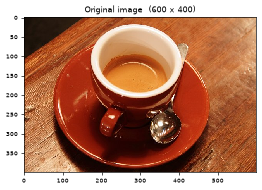

In [2]:
def load_image(path):
    # Load an image file as an RGB uint8 array, or raise ValueError with a clear message.
    if not isinstance(path, str) or path.strip() == "":
        raise ValueError("Image path must be a non-empty string.")
    if not os.path.isfile(path):
        raise ValueError("File not found: %r" % path)
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)           # returns None if decoding fails
    if bgr is None:
        raise ValueError("File exists but could not be decoded as an image: %r" % path)
    if bgr.ndim != 3 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise ValueError("Image has zero width or height: %r" % path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)        # BGR -> RGB (consistent colour handling)


def save_image(rgb, filename):
    # Save an RGB image into OUTPUT_DIR as a JPEG and return the path.
    path = os.path.join(OUTPUT_DIR, filename)
    ok = cv2.imwrite(path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
    if not ok:
        raise IOError("Could not write file: %s" % path)
    saved_files.append(path)
    return path


original = load_image(INPUT_PATH)
original_hash = hashlib.md5(original.tobytes()).hexdigest()   # fingerprint, to prove it stays unchanged
original.flags.writeable = False                              # any accidental in-place change would raise an error

height, width = original.shape[:2]
print("File         :", INPUT_PATH)
print("Width        :", width, "px")
print("Height       :", height, "px")
print("Array shape  :", original.shape, " (height, width, channels)")
print("Data type    :", original.dtype)

plt.figure(figsize=(5, 3.4))
plt.imshow(original, interpolation="nearest")
plt.title("Original image  (%d x %d)" % (width, height), fontsize=9)
plt.tick_params(labelsize=7)
plt.show()

**Loader validation examples** – a missing file and a file that is not a real image are both rejected with a clear message (no crash).

In [3]:
# (a) file that does not exist
try:
    load_image("this_file_does_not_exist.jpg")
except ValueError as err:
    print("REJECTED  ->", err)

# (b) file that exists but is not a valid image (a text file with a .jpg name)
tmp = tempfile.NamedTemporaryFile(suffix=".jpg", delete=False)
tmp.write(b"this is not image data")
tmp.close()
try:
    load_image(tmp.name)
except ValueError as err:
    print("REJECTED  ->", err.args[0].split(":")[0] + ": (temporary file)")
finally:
    os.remove(tmp.name)

REJECTED  -> File not found: 'this_file_does_not_exist.jpg'
REJECTED  -> File exists but could not be decoded as an image: (temporary file)


## 2. The reusable `transform()` function

```
transform(image, operation, **params)  ->  transformed image
```

| Operation | Required parameters | Rules |
|---|---|---|
| `scale` | `sx`, `sy`, `interpolation` | finite factors > 0; output size >= 1 px and <= declared maximum; interpolation in nearest / bilinear / bicubic / lanczos |
| `crop` | `left`, `top`, `right`, `bottom` | integers; `0 <= left < right <= width`, `0 <= top < bottom <= height` (right and bottom are exclusive) |
| `flip` | `direction` | `horizontal`, `vertical` or `both` |
| `translate` | `tx`, `ty` | any finite number (positive, negative or zero); canvas size is kept |
| `rotate` | `angle`, `expand` | any finite angle in degrees (positive = **counter-clockwise**); `expand` must be True / False |

Validation happens **inside** `transform` (types, NaN / infinity, ranges, unknown or missing parameters). Nothing is silently replaced by a default value – a bad input raises `TransformError` with a clear message.

In [4]:
class TransformError(ValueError):
    # Raised for any invalid image, operation name or parameter value.
    pass


INTERPOLATIONS = {
    "nearest":  cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic":  cv2.INTER_CUBIC,
    "lanczos":  cv2.INTER_LANCZOS4,
}
FLIP_CODES = {"horizontal": 1, "vertical": 0, "both": -1}     # cv2.flip codes

# required parameters of each operation (single source of truth, also used by the prompts)
REQUIRED_PARAMS = {
    "scale":     ("sx", "sy", "interpolation"),
    "crop":      ("left", "top", "right", "bottom"),
    "flip":      ("direction",),
    "translate": ("tx", "ty"),
    "rotate":    ("angle", "expand"),
}


# ------------------------------------------------------------ small validators
def _check_finite_number(name, value):
    # Accept int/float (not bool, not text); reject NaN and infinity.
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TransformError("'%s' must be a number, got %r (%s)." % (name, value, type(value).__name__))
    try:
        number = float(value)
    except OverflowError:
        raise TransformError("'%s' is too large to be used." % name) from None
    if not math.isfinite(number):
        raise TransformError("'%s' must be finite (NaN and infinity are not allowed), got %s." % (name, number))
    return number


def _check_integer(name, value):
    # Accept whole numbers only (3 is fine, 3.5 and '3' are not).
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
        raise TransformError("'%s' must be a whole number (integer), got %r." % (name, value))
    return int(value)


def _check_choice(name, value, allowed):
    # Accept one of the allowed words (case-insensitive).
    if not isinstance(value, str) or value.strip().lower() not in allowed:
        raise TransformError("'%s' must be one of %s, got %r." % (name, list(allowed), value))
    return value.strip().lower()


def _check_bool(name, value):
    if not isinstance(value, (bool, np.bool_)):
        raise TransformError("'%s' must be True or False, got %r." % (name, value))
    return bool(value)


def _check_image(image):
    if not isinstance(image, np.ndarray):
        raise TransformError("image must be a NumPy array, got %s." % type(image).__name__)
    if image.dtype != np.uint8:
        raise TransformError("image must have dtype uint8, got %s." % image.dtype)
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise TransformError("image must be 2-D or have 1, 3 or 4 channels, got shape %s." % (image.shape,))
    if image.shape[0] == 0 or image.shape[1] == 0:
        raise TransformError("image has zero width or height, shape %s." % (image.shape,))


def _check_output_size(out_w, out_h, what):
    # Declared maximum output size is enforced here.
    if out_w < 1 or out_h < 1:
        raise TransformError("%s would produce an empty image (%d x %d px)." % (what, out_w, out_h))
    if out_w > MAX_OUTPUT_SIDE or out_h > MAX_OUTPUT_SIDE or out_w * out_h > MAX_OUTPUT_PIXELS:
        raise TransformError("%s would produce %d x %d px, above the allowed maximum (%d px per side, %d px total)."
                             % (what, out_w, out_h, MAX_OUTPUT_SIDE, MAX_OUTPUT_PIXELS))


# ------------------------------------------------------------ the five operations
def _scale(image, sx, sy, interpolation):
    sx = _check_finite_number("sx", sx)
    sy = _check_finite_number("sy", sy)
    if sx <= 0 or sy <= 0:
        raise TransformError("Scale factors must be greater than zero (sx=%s, sy=%s)." % (sx, sy))
    method = _check_choice("interpolation", interpolation, INTERPOLATIONS)
    h, w = image.shape[:2]
    new_w_float, new_h_float = w * sx, h * sy
    if not (math.isfinite(new_w_float) and math.isfinite(new_h_float)):
        raise TransformError("Scale factors are so large that the output size is not representable.")
    new_w = int(math.floor(new_w_float + 0.5))        # round half up -> integer pixels
    new_h = int(math.floor(new_h_float + 0.5))
    _check_output_size(new_w, new_h, "Scaling by sx=%s, sy=%s" % (sx, sy))
    return cv2.resize(image, (new_w, new_h), interpolation=INTERPOLATIONS[method])


def _crop(image, left, top, right, bottom):
    left = _check_integer("left", left)
    top = _check_integer("top", top)
    right = _check_integer("right", right)
    bottom = _check_integer("bottom", bottom)
    h, w = image.shape[:2]
    if not (0 <= left < right <= w):
        raise TransformError("Invalid horizontal crop: need 0 <= left < right <= width (%d), got left=%d, right=%d."
                             % (w, left, right))
    if not (0 <= top < bottom <= h):
        raise TransformError("Invalid vertical crop: need 0 <= top < bottom <= height (%d), got top=%d, bottom=%d."
                             % (h, top, bottom))
    return image[top:bottom, left:right].copy()       # right / bottom are exclusive


def _flip(image, direction):
    direction = _check_choice("direction", direction, FLIP_CODES)
    return cv2.flip(image, FLIP_CODES[direction])


def _translate(image, tx, ty):
    tx = _check_finite_number("tx", tx)
    ty = _check_finite_number("ty", ty)
    h, w = image.shape[:2]
    # An offset larger than the canvas already pushes everything out of view, so clamping
    # it changes nothing visible but keeps the arithmetic safe for extreme values.
    tx = max(-(w + 1.0), min(w + 1.0, tx))
    ty = max(-(h + 1.0), min(h + 1.0, ty))
    M = np.array([[1.0, 0.0, tx],
                  [0.0, 1.0, ty]], dtype=np.float64)   # +tx = right, +ty = down
    return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)   # same canvas, black background


def _rotate(image, angle, expand):
    angle = _check_finite_number("angle", angle)
    expand = _check_bool("expand", expand)
    h, w = image.shape[:2]
    angle = math.fmod(angle, 360.0)                   # 370 deg == 10 deg, keeps huge angles safe
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0             # rotate about the image centre
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0) # positive angle = counter-clockwise
    out_w, out_h = w, h
    if expand:
        cos_a, sin_a = abs(M[0, 0]), abs(M[0, 1])
        out_w = max(1, int(math.ceil(w * cos_a + h * sin_a - 1e-6)))   # bounding box of the rotated image
        out_h = max(1, int(math.ceil(h * cos_a + w * sin_a - 1e-6)))
        _check_output_size(out_w, out_h, "Rotation by %s degrees with expand=True" % angle)
        M[0, 2] += (out_w - 1) / 2.0 - cx             # move the rotated centre to the new canvas centre
        M[1, 2] += (out_h - 1) / 2.0 - cy
    return cv2.warpAffine(image, M, (out_w, out_h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)


_OPERATIONS = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}


# ------------------------------------------------------------ the single entry point
def transform(image, operation, **params):
    # Apply one geometric operation and return the NEW image (the input is never modified).
    _check_image(image)
    if not isinstance(operation, str) or operation.strip().lower() not in REQUIRED_PARAMS:
        raise TransformError("Unknown operation %r. Supported operations: %s." % (operation, list(REQUIRED_PARAMS)))
    op = operation.strip().lower()
    required = REQUIRED_PARAMS[op]
    missing = [name for name in required if name not in params]
    if missing:
        raise TransformError("Operation '%s' is missing required parameter(s): %s." % (op, missing))
    unexpected = [name for name in params if name not in required]
    if unexpected:
        raise TransformError("Operation '%s' does not accept parameter(s): %s. It needs: %s."
                             % (op, unexpected, list(required)))
    return _OPERATIONS[op](image, **params)


print("transform() is ready. Operations:", list(REQUIRED_PARAMS))

transform() is ready. Operations: ['scale', 'crop', 'flip', 'translate', 'rotate']


### Helper functions for labelled comparison figures

In [5]:
def describe(op, params, out):
    # Label text: operation, parameters and output dimensions.
    ptxt = ", ".join("%s=%s" % (k, v) for k, v in params.items())
    ptxt = "\n".join(textwrap.wrap(ptxt, 34))
    return "%s\n%s\noutput: %d x %d (W x H)" % (op.upper(), ptxt, out.shape[1], out.shape[0])


def show_comparison(original_img, items, original_label=None, box=None):
    # Show the original followed by transformed images. items = [(image, label), ...]
    # box = (left, top, right, bottom) draws the crop rectangle on the original.
    n = len(items) + 1
    fig, axes = plt.subplots(1, n, figsize=(3.3 * n, 3.6))
    axes = np.atleast_1d(axes)
    if original_label is None:
        original_label = "ORIGINAL\n\noutput: %d x %d (W x H)" % (original_img.shape[1], original_img.shape[0])
    axes[0].imshow(original_img, interpolation="nearest")
    axes[0].set_title(original_label, fontsize=8)
    if box is not None:
        l, t, r, b = box
        axes[0].add_patch(Rectangle((l - 0.5, t - 0.5), r - l, b - t, fill=False, edgecolor="red", linewidth=2))
    for ax, (img, label) in zip(axes[1:], items):
        ax.imshow(img, interpolation="nearest")
        ax.set_title(label, fontsize=8)
    for ax in axes:
        ax.tick_params(labelsize=6)
    plt.tight_layout()
    plt.show()


def run_cases(op, cases, show_box=False, original_img=None):
    # Run several (file_stem, params) cases of one operation, save and show them.
    src = original if original_img is None else original_img
    items = []
    for stem, params in cases:
        out = transform(src, op, **params)
        save_image(out, stem + ".jpg")
        items.append((out, describe(op, params, out)))
    box = None
    if show_box:
        p = cases[0][1]
        box = (p["left"], p["top"], p["right"], p["bottom"])
    show_comparison(src, items, box=box)
    return [img for img, _ in items]

## 3. Interactive input (user selects the operation and types the parameters)

The user is asked for the operation and then for each parameter. Typed text is validated **before** it reaches `transform()`:
* non-numeric text, `nan` and `inf` are rejected,
* zero and negative numbers are accepted where the rules allow them,
* on a mistake a clear message is shown and the same question is asked again (no crash).

Type `q` at any prompt to finish.

**How to use it:** `LIVE_MODE = False` (default) runs a *scripted* session that contains deliberate typing mistakes, so the outputs of a "Run All" are fully visible. Set `LIVE_MODE = True` and run the last cell of this section to type your own values.

In [6]:
class QuitSession(Exception):
    # Raised when the user types q.
    pass


def _read(ask, prompt):
    text = ask(prompt)
    text = "q" if text is None else str(text).strip()
    if text.lower() in ("q", "quit", "exit"):
        raise QuitSession()
    return text


# ---- text -> value converters (they raise TransformError with friendly messages) ----
def parse_float_text(name, text):
    if text == "" or "_" in text:
        raise TransformError("'%s': please type a number, got %r." % (name, text))
    try:
        value = float(text)
    except ValueError:
        raise TransformError("'%s': %r is not a number." % (name, text)) from None
    if not math.isfinite(value):
        raise TransformError("'%s': NaN and infinity (%r) are not allowed." % (name, text))
    return value


def parse_int_text(name, text):
    if text == "" or "_" in text:
        raise TransformError("'%s': please type a whole number, got %r." % (name, text))
    try:
        return int(text)
    except ValueError:
        raise TransformError("'%s': %r is not a whole number." % (name, text)) from None


def parse_choice_text(name, text, allowed):
    if text.lower() not in allowed:
        raise TransformError("'%s': %r is not allowed. Choose one of %s." % (name, text, list(allowed)))
    return text.lower()


def parse_bool_text(name, text):
    if text.lower() in ("yes", "y", "true", "1"):
        return True
    if text.lower() in ("no", "n", "false", "0"):
        return False
    raise TransformError("'%s': please answer yes or no, got %r." % (name, text))


# (parameter name, kind, allowed words, prompt text) for every operation
PARAM_PROMPTS = {
    "scale": [("sx", "float", None, "Horizontal scale factor sx (> 0)"),
              ("sy", "float", None, "Vertical scale factor sy (> 0)"),
              ("interpolation", "choice", tuple(INTERPOLATIONS), "Interpolation")],
    "crop": [("left", "int", None, "left   (x of the left edge)"),
             ("top", "int", None, "top    (y of the top edge)"),
             ("right", "int", None, "right  (x of the right edge, exclusive)"),
             ("bottom", "int", None, "bottom (y of the bottom edge, exclusive)")],
    "flip": [("direction", "choice", tuple(FLIP_CODES), "Flip direction")],
    "translate": [("tx", "float", None, "Horizontal offset tx in pixels (+ = right)"),
                  ("ty", "float", None, "Vertical offset ty in pixels (+ = down)")],
    "rotate": [("angle", "float", None, "Angle in degrees (+ = counter-clockwise)"),
               ("expand", "bool", None, "Expand the canvas? (yes/no)")],
}
# safety check: prompts and transform() agree on the parameter names
assert {k: tuple(p[0] for p in v) for k, v in PARAM_PROMPTS.items()} == REQUIRED_PARAMS


def ask_parameter(ask, spec):
    # Keep asking for ONE parameter until a valid value is typed.
    name, kind, allowed, label = spec
    hint = " [%s]" % "/".join(allowed) if allowed else ""
    while True:
        text = _read(ask, "  %s%s: " % (label, hint))
        try:
            if kind == "float":
                return parse_float_text(name, text)
            if kind == "int":
                return parse_int_text(name, text)
            if kind == "choice":
                return parse_choice_text(name, text, allowed)
            return parse_bool_text(name, text)
        except TransformError as err:
            print("    ERROR: %s  -> try again (or type q to quit)." % err)


def interactive_session(image, ask=input):
    # Ask for an operation and its parameters, call transform(), show and save the result.
    ops = list(REQUIRED_PARAMS)
    count = 0
    while True:
        try:
            op = _read(ask, "Operation %s (q = quit): " % ops).lower()
            if op not in REQUIRED_PARAMS:
                print("    ERROR: unknown operation %r. Choose one of %s." % (op, ops))
                continue
            while True:
                params = {spec[0]: ask_parameter(ask, spec) for spec in PARAM_PROMPTS[op]}
                try:
                    out = transform(image, op, **params)
                except TransformError as err:          # e.g. a crop box outside the image
                    print("    ERROR: %s\n    -> please enter the parameters again." % err)
                    continue
                break
        except QuitSession:
            print("Session finished.")
            break
        count += 1
        save_image(out, "interactive_%d_%s.jpg" % (count, op))
        print("    OK: %s\n" % describe(op, params, out).replace("\n", " "))
        show_comparison(image, [(out, describe(op, params, out))])
    return count


def make_scripted_ask(answers):
    # Replacement for input() that 'types' the given answers one by one (and prints them).
    answer_iter = iter(answers)
    def ask(prompt):
        answer = next(answer_iter, "q")               # when the script ends, behave like 'q'
        print(prompt + str(answer))
        return answer
    return ask


print("Interactive helpers are ready.")

Interactive helpers are ready.


**Interactive session** (scripted by default – it contains typing mistakes on purpose: unknown operation, non-numeric value, bad interpolation, invalid crop box, bad flip direction, `nan`, `inf`, bad yes/no).

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): blur
    ERROR: unknown operation 'blur'. Choose one of ['scale', 'crop', 'flip', 'translate', 'rotate'].
Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): scale
  Horizontal scale factor sx (> 0): abc
    ERROR: 'sx': 'abc' is not a number.  -> try again (or type q to quit).
  Horizontal scale factor sx (> 0): 1.5
  Vertical scale factor sy (> 0): 0.75
  Interpolation [nearest/bilinear/bicubic/lanczos]: cubic-spline
    ERROR: 'interpolation': 'cubic-spline' is not allowed. Choose one of ['nearest', 'bilinear', 'bicubic', 'lanczos'].  -> try again (or type q to quit).
  Interpolation [nearest/bilinear/bicubic/lanczos]: bicubic
    OK: SCALE sx=1.5, sy=0.75, interpolation=bicubic output: 900 x 300 (W x H)



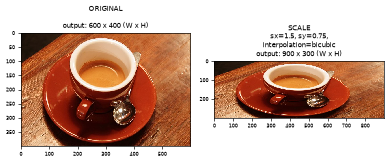

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): crop
  left   (x of the left edge): 100
  top    (y of the top edge): 50
  right  (x of the right edge, exclusive): 40
  bottom (y of the bottom edge, exclusive): 300
    ERROR: Invalid horizontal crop: need 0 <= left < right <= width (600), got left=100, right=40.
    -> please enter the parameters again.
  left   (x of the left edge): 160
  top    (y of the top edge): 10
  right  (x of the right edge, exclusive): 420
  bottom (y of the bottom edge, exclusive): 300
    OK: CROP left=160, top=10, right=420, bottom=300 output: 260 x 290 (W x H)



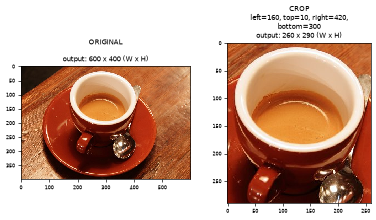

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): flip
  Flip direction [horizontal/vertical/both]: diagonal
    ERROR: 'direction': 'diagonal' is not allowed. Choose one of ['horizontal', 'vertical', 'both'].  -> try again (or type q to quit).
  Flip direction [horizontal/vertical/both]: both
    OK: FLIP direction=both output: 600 x 400 (W x H)



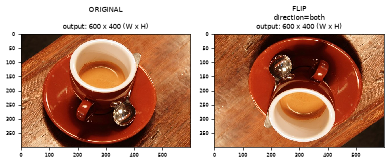

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): translate
  Horizontal offset tx in pixels (+ = right): -60
  Vertical offset ty in pixels (+ = down): nan
    ERROR: 'ty': NaN and infinity ('nan') are not allowed.  -> try again (or type q to quit).
  Vertical offset ty in pixels (+ = down): 25
    OK: TRANSLATE tx=-60.0, ty=25.0 output: 600 x 400 (W x H)



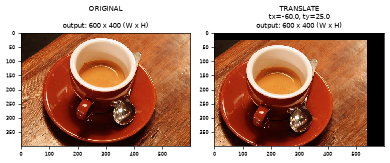

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): rotate
  Angle in degrees (+ = counter-clockwise): inf
    ERROR: 'angle': NaN and infinity ('inf') are not allowed.  -> try again (or type q to quit).
  Angle in degrees (+ = counter-clockwise): -30
  Expand the canvas? (yes/no): maybe
    ERROR: 'expand': please answer yes or no, got 'maybe'.  -> try again (or type q to quit).
  Expand the canvas? (yes/no): yes
    OK: ROTATE angle=-30.0, expand=True output: 720 x 647 (W x H)



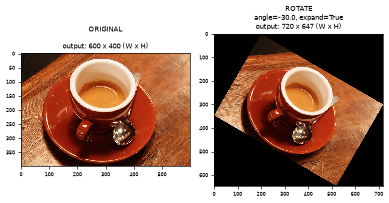

Operation ['scale', 'crop', 'flip', 'translate', 'rotate'] (q = quit): q
Session finished.
Scripted session completed: 5 operations applied.


In [7]:
LIVE_MODE = False        # False = scripted demo session | True = type your own values

scripted_answers = [
    "blur",                          # unknown operation          -> rejected
    "scale", "abc", "1.5", "0.75",   # sx: non-numeric -> rejected, then 1.5 ; sy = 0.75
    "cubic-spline", "bicubic",       # unsupported interpolation -> rejected, then bicubic
    "crop", "100", "50", "40", "300",# right (40) <= left (100)   -> rejected by transform, ask again
    "160", "10", "420", "300",       # valid crop box
    "flip", "diagonal", "both",      # unsupported direction -> rejected, then both
    "translate", "-60", "nan", "25", # ty = nan -> rejected, then 25  (negative tx is accepted)
    "rotate", "inf", "-30", "maybe", "yes",   # angle = inf rejected, -30 ok ; expand 'maybe' rejected, then yes
    "q",
]

if LIVE_MODE:
    try:
        interactive_session(original, ask=input)
    except RuntimeError as err:      # happens if the notebook has no keyboard input (e.g. batch run)
        print("Keyboard input is not available here (%s). Set LIVE_MODE = False." % type(err).__name__)
else:
    n_done = interactive_session(original, ask=make_scripted_ask(scripted_answers))
    print("Scripted session completed: %d operations applied." % n_done)

## 4. Demonstration of every operation (custom values)

Each figure shows the original and the results, labelled with the **operation, parameters and output dimensions**. Every result is saved in the `outputs/` folder.

### 4.1 Scaling – enlargement, reduction and non-proportional scaling

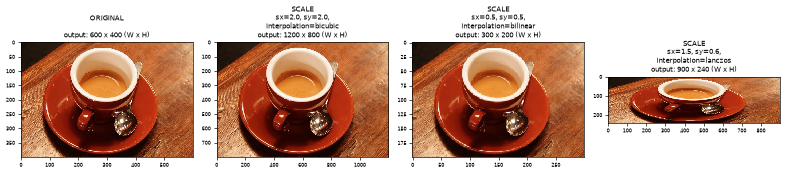

In [8]:
scale_cases = [
    ("scale_enlarge_2x_bicubic",    dict(sx=2.0, sy=2.0, interpolation="bicubic")),   # enlargement
    ("scale_reduce_half_bilinear",  dict(sx=0.5, sy=0.5, interpolation="bilinear")),  # reduction
    ("scale_nonprop_lanczos",       dict(sx=1.5, sy=0.6, interpolation="lanczos")),   # non-proportional (sx != sy)
]
scale_results = run_cases("scale", scale_cases)

### 4.2 Cropping (red rectangle = crop region; right and bottom are exclusive)

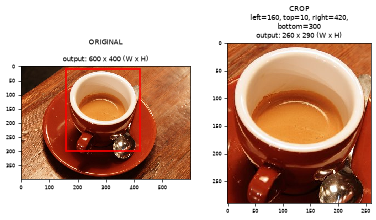

In [9]:
crop_cases = [
    ("crop_center_region", dict(left=160, top=10, right=420, bottom=300)),
]
crop_results = run_cases("crop", crop_cases, show_box=True)

### 4.3 Flipping – horizontal, vertical, both

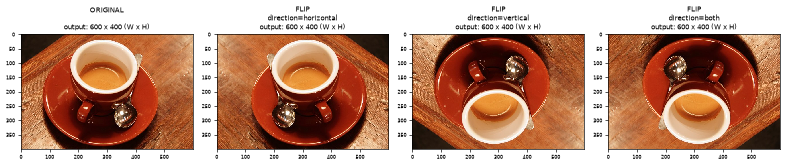

In [10]:
flip_cases = [
    ("flip_horizontal", dict(direction="horizontal")),
    ("flip_vertical",   dict(direction="vertical")),
    ("flip_both",       dict(direction="both")),
]
flip_results = run_cases("flip", flip_cases)

### 4.4 Translation – shifts in opposite directions (canvas size is kept, exposed areas are black)

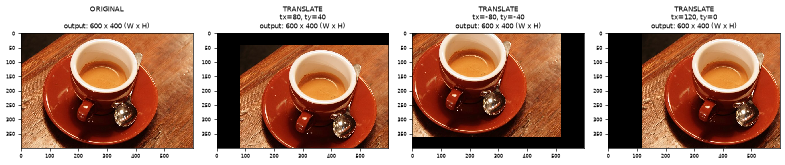

In [11]:
translate_cases = [
    ("translate_right_down", dict(tx=80,  ty=40)),    # right and down
    ("translate_left_up",    dict(tx=-80, ty=-40)),   # opposite direction: left and up
    ("translate_right_only", dict(tx=120, ty=0)),     # zero offset on one axis is valid
]
translate_results = run_cases("translate", translate_cases)

### 4.5 Rotation – positive and negative angles, with and without canvas expansion
Positive angle = **counter-clockwise**; rotation is about the image centre.

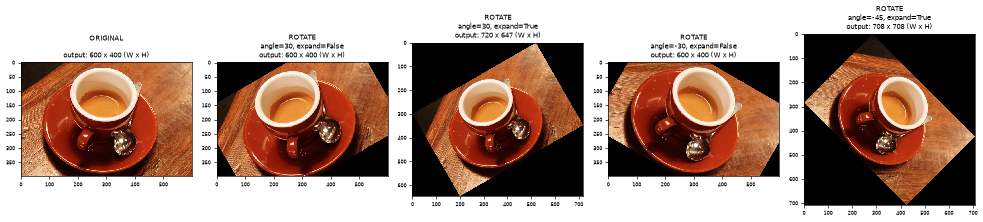

In [12]:
rotate_cases = [
    ("rotate_plus30_noexpand",  dict(angle=30,  expand=False)),
    ("rotate_plus30_expand",    dict(angle=30,  expand=True)),
    ("rotate_minus30_noexpand", dict(angle=-30, expand=False)),
    ("rotate_minus45_expand",   dict(angle=-45, expand=True)),
]
rotate_results = run_cases("rotate", rotate_cases)

## 5. Interpolation comparison on the same enlarged image patch

A small 48 x 36 pixel patch (sharp edge of the spoon) is cut out with `transform(..., "crop", ...)` and enlarged **8 times** using each interpolation method.

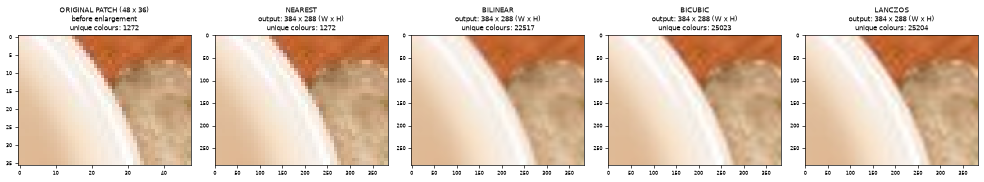

In [13]:
patch_box = dict(left=370, top=60, right=418, bottom=96)       # 48 x 36 px patch
patch = transform(original, "crop", **patch_box)

interp_items = []
for method in INTERPOLATIONS:                                      # nearest, bilinear, bicubic, lanczos
    big = transform(patch, "scale", sx=8, sy=8, interpolation=method)
    save_image(big, "interp_%s.jpg" % method)
    colours = len(np.unique(big.reshape(-1, 3), axis=0))
    interp_items.append((big, "%s\noutput: %d x %d (W x H)\nunique colours: %d"
                         % (method.upper(), big.shape[1], big.shape[0], colours)))

show_comparison(patch, interp_items,
                original_label="ORIGINAL PATCH (48 x 36)\nbefore enlargement\nunique colours: %d"
                % len(np.unique(patch.reshape(-1, 3), axis=0)))

**Observations**

* **Nearest-neighbour** simply repeats the closest pixel. The result is blocky with staircase (jagged) edges, but it creates **no new colours** (the unique-colour count stays equal to the original patch).
* **Bilinear** averages the 4 nearest pixels. Edges become smooth, but the lines look softer / slightly blurred.
* **Bicubic** uses a 4 x 4 neighbourhood. Lines are smoother than nearest and noticeably sharper than bilinear; a faint light/dark halo can appear next to strong edges.
* **Lanczos** uses an 8 x 8 neighbourhood. It gives the sharpest, cleanest lines of the smooth methods, but it can show slight ringing (light/dark halos) next to high-contrast edges.

## 6. Rejected inputs (at least one for every operation)

Every row below is passed to `transform()` and **must** raise `TransformError`. The notebook catches the error and prints the message, so nothing crashes.

In [14]:
rejected_cases = [
    # (operation, parameters, what is wrong)
    ("scale",     dict(sx=0, sy=1, interpolation="bilinear"),         "zero scale factor"),
    ("scale",     dict(sx=-2, sy=1, interpolation="bilinear"),        "negative scale factor"),
    ("scale",     dict(sx="abc", sy=1, interpolation="bilinear"),     "non-numeric factor"),
    ("scale",     dict(sx=0.0001, sy=0.0001, interpolation="nearest"),"output would be 0 x 0 (empty image)"),
    ("scale",     dict(sx=20, sy=20, interpolation="bicubic"),        "output above the declared maximum size"),
    ("scale",     dict(sx=2, sy=2, interpolation="cubic-spline"),     "unsupported interpolation"),
    ("crop",      dict(left=300, top=50, right=100, bottom=200),      "right <= left"),
    ("crop",      dict(left=0, top=0, right=700, bottom=200),         "right is larger than the width"),
    ("crop",      dict(left=-5, top=0, right=100, bottom=100),        "negative coordinate"),
    ("crop",      dict(left=10.5, top=0, right=100, bottom=100),      "non-integer coordinate"),
    ("flip",      dict(direction="diagonal"),                         "unsupported direction"),
    ("flip",      dict(direction=5),                                  "direction is not text"),
    ("translate", dict(tx="abc", ty=10),                              "non-numeric offset"),
    ("translate", dict(tx=float("nan"), ty=10),                       "NaN offset"),
    ("translate", dict(tx=10, ty=float("inf")),                       "infinite offset"),
    ("rotate",    dict(angle="abc", expand=True),                     "non-numeric angle"),
    ("rotate",    dict(angle=float("nan"), expand=True),              "NaN angle"),
    ("rotate",    dict(angle=float("inf"), expand=False),             "infinite angle"),
    ("rotate",    dict(angle=45, expand="maybe"),                     "invalid expand choice"),
    ("blur",      dict(radius=3),                                     "unknown operation"),
    ("scale",     dict(sx=2, interpolation="bilinear"),               "missing required parameter sy"),
    ("flip",      dict(direction="both", extra=1),                    "unexpected extra parameter"),
]

rows = []
for op, params, why in rejected_cases:
    try:
        transform(original, op, **params)
        message = "!! ACCEPTED (unexpected) !!"
    except TransformError as err:
        message = "REJECTED: " + str(err)
    rows.append((op, why, message))

print("%-10s | %-40s | %s" % ("Operation", "What is wrong", "Message from transform()"))
print("-" * 130)
for op, why, message in rows:
    lines = textwrap.wrap(message, 70) or [""]
    print("%-10s | %-40s | %s" % (op, why, lines[0]))
    for extra_line in lines[1:]:
        print("%-10s | %-40s | %s" % ("", "", extra_line))

# an invalid IMAGE is rejected too
for bad_image in (None, np.zeros((0, 10, 3), np.uint8)):
    try:
        transform(bad_image, "flip", direction="both")
    except TransformError as err:
        print("\nInvalid image -> REJECTED:", err)

Operation  | What is wrong                            | Message from transform()
----------------------------------------------------------------------------------------------------------------------------------
scale      | zero scale factor                        | REJECTED: Scale factors must be greater than zero (sx=0.0, sy=1.0).
scale      | negative scale factor                    | REJECTED: Scale factors must be greater than zero (sx=-2.0, sy=1.0).
scale      | non-numeric factor                       | REJECTED: 'sx' must be a number, got 'abc' (str).
scale      | output would be 0 x 0 (empty image)      | REJECTED: Scaling by sx=0.0001, sy=0.0001 would produce an empty image
           |                                          | (0 x 0 px).
scale      | output above the declared maximum size   | REJECTED: Scaling by sx=20.0, sy=20.0 would produce 12000 x 8000 px,
           |                                          | above the allowed maximum (4000 px per side, 12000000 px 

**Boundary values that must be *accepted*** (zero offsets, zero angle, negative offsets and negative angles):

In [15]:
accepted_cases = [
    ("translate", dict(tx=0, ty=0)),
    ("translate", dict(tx=-30, ty=-10)),
    ("translate", dict(tx=0, ty=25)),
    ("rotate",    dict(angle=0, expand=False)),
    ("rotate",    dict(angle=-90, expand=True)),
    ("rotate",    dict(angle=370, expand=False)),
    ("crop",      dict(left=0, top=0, right=width, bottom=height)),    # full image
    ("scale",     dict(sx=1, sy=1, interpolation="nearest")),
]
for op, params in accepted_cases:
    out = transform(original, op, **params)
    print("ACCEPTED  %-10s %-45s -> output %d x %d" % (op, params, out.shape[1], out.shape[0]))

ACCEPTED  translate  {'tx': 0, 'ty': 0}                            -> output 600 x 400
ACCEPTED  translate  {'tx': -30, 'ty': -10}                        -> output 600 x 400
ACCEPTED  translate  {'tx': 0, 'ty': 25}                           -> output 600 x 400
ACCEPTED  rotate     {'angle': 0, 'expand': False}                 -> output 600 x 400
ACCEPTED  rotate     {'angle': -90, 'expand': True}                -> output 400 x 600
ACCEPTED  rotate     {'angle': 370, 'expand': False}               -> output 600 x 400
ACCEPTED  crop       {'left': 0, 'top': 0, 'right': 600, 'bottom': 400} -> output 600 x 400
ACCEPTED  scale      {'sx': 1, 'sy': 1, 'interpolation': 'nearest'} -> output 600 x 400


## 7. Identity checks (Pass / Fail)

An identity case must give back an image that is **exactly equal** to the original (same shape and every pixel equal).

In [16]:
identity_cases = [
    ("Translation tx=0, ty=0",              "translate", dict(tx=0, ty=0)),
    ("Scale sx=1, sy=1 (nearest)",          "scale",     dict(sx=1, sy=1, interpolation="nearest")),
    ("Scale sx=1, sy=1 (bilinear)",         "scale",     dict(sx=1, sy=1, interpolation="bilinear")),
    ("Scale sx=1, sy=1 (bicubic)",          "scale",     dict(sx=1, sy=1, interpolation="bicubic")),
    ("Scale sx=1, sy=1 (lanczos)",          "scale",     dict(sx=1, sy=1, interpolation="lanczos")),
    ("Rotation 0 deg, expand=False",        "rotate",    dict(angle=0, expand=False)),
    ("Rotation 0 deg, expand=True",         "rotate",    dict(angle=0, expand=True)),
    ("Rotation 360 deg, expand=False",      "rotate",    dict(angle=360, expand=False)),
    ("Crop of the full image",              "crop",      dict(left=0, top=0, right=width, bottom=height)),
]

table = []
for name, op, params in identity_cases:
    out = transform(original, op, **params)
    same_shape = out.shape == original.shape
    max_diff = int(np.abs(out.astype(np.int16) - original.astype(np.int16)).max()) if same_shape else -1
    passed = same_shape and max_diff == 0
    table.append((name, "same size, all pixels equal",
                  "size %dx%d, max pixel difference %s" % (out.shape[1], out.shape[0], max_diff if same_shape else "n/a"),
                  "PASS" if passed else "FAIL"))

# extra check: two horizontal flips give the original back
twice = transform(transform(original, "flip", direction="horizontal"), "flip", direction="horizontal")
ok = np.array_equal(twice, original)
table.append(("Horizontal flip applied twice", "same size, all pixels equal",
              "size %dx%d, equal to original: %s" % (twice.shape[1], twice.shape[0], ok), "PASS" if ok else "FAIL"))

print("%-34s | %-28s | %-42s | %s" % ("Test case", "Expected behaviour", "Actual behaviour", "Result"))
print("-" * 120)
for row in table:
    print("%-34s | %-28s | %-42s | %s" % row)
print("\nTotal: %d tests, %d passed" % (len(table), sum(r[3] == "PASS" for r in table)))

Test case                          | Expected behaviour           | Actual behaviour                           | Result
------------------------------------------------------------------------------------------------------------------------
Translation tx=0, ty=0             | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Scale sx=1, sy=1 (nearest)         | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Scale sx=1, sy=1 (bilinear)        | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Scale sx=1, sy=1 (bicubic)         | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Scale sx=1, sy=1 (lanczos)         | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Rotation 0 deg, expand=False       | same size, all pixels equal  | size 600x400, max pixel difference 0       | PASS
Rotation 0 deg, expand=True        | same size, all

## 8. Concept notes

**Image coordinates vs. array indexing.** In *image coordinates* a point is written `(x, y)`: `x` runs to the right, `y` runs **downwards**, and the origin `(0, 0)` is the top-left corner. A NumPy image array is indexed the other way round: `image[row, column]` = `image[y, x]`, and its shape is `(height, width, channels)`. This is why `original.shape` prints height first, while OpenCV functions such as `cv2.resize` and `cv2.warpAffine` want the size as `(width, height)`. Crop is written with array slicing `image[top:bottom, left:right]`, so `right` and `bottom` are exclusive.

**Aspect-ratio distortion.** The aspect ratio is `width / height`. It is preserved only when `sx == sy`. With `sx != sy` (for example `sx=1.5, sy=0.6` above) the image is stretched in one direction and squeezed in the other, so the round cup and saucer turn into ellipses

**Rotation canvas expansion.** With `expand=False` the canvas keeps its size, so the corners of the rotated image are **cut off** and empty black triangles appear. With `expand=True` the canvas grows to the bounding box of the rotated image, `new_w = w*|cos a| + h*|sin a|` and `new_h = h*|cos a| + w*|sin a|`, so nothing is lost, but the output is larger and has black corners. Positive angles turn the image **counter-clockwise** about its centre.

**Translation clipping.** Translation keeps the original canvas size. Pixels pushed outside the canvas are **lost (clipped)**, and the area uncovered on the opposite side is filled with black (background value 0). Moving the image back does not restore the lost pixels, as the check below shows.

In [17]:
shifted = transform(original, "translate", tx=80, ty=40)
back = transform(shifted, "translate", tx=-80, ty=-40)
lost = np.any(back != original, axis=2)
print("Shift by (+80, +40) and then by (-80, -40):")
print("  pixels that could NOT be restored: %d of %d (%.1f %%)" % (lost.sum(), lost.size, 100.0 * lost.mean()))
print("  -> the strips that left the canvas (80 px on the right, 40 px at the bottom) are gone for good.")

Shift by (+80, +40) and then by (-80, -40):
  pixels that could NOT be restored: 52800 of 240000 (22.0 %)
  -> the strips that left the canvas (80 px on the right, 40 px at the bottom) are gone for good.


## 9. Summary: saved files and final checks

In [18]:
print("Saved transformed images (JPEG, quality %d):" % JPEG_QUALITY)
total_kb = 0.0
for path in saved_files:
    kb = os.path.getsize(path) / 1024.0
    total_kb += kb
    print("  %-48s %6.1f KB" % (path, kb))
print("\nFiles saved   : %d" % len(saved_files))
print("Total size    : %.1f KB (%.2f MB)" % (total_kb, total_kb / 1024.0))
print("Input image   : %s (%.1f KB)" % (INPUT_PATH, os.path.getsize(INPUT_PATH) / 1024.0))

unchanged = hashlib.md5(original.tobytes()).hexdigest() == original_hash
print("\nOriginal image unchanged after all operations:", unchanged)

Saved transformed images (JPEG, quality 90):
  outputs\interactive_1_scale.jpg                    73.5 KB
  outputs\interactive_2_crop.jpg                     21.2 KB
  outputs\interactive_3_flip.jpg                     66.5 KB
  outputs\interactive_4_translate.jpg                58.1 KB
  outputs\interactive_5_rotate.jpg                   71.2 KB
  outputs\scale_enlarge_2x_bicubic.jpg              171.5 KB
  outputs\scale_reduce_half_bilinear.jpg             21.1 KB
  outputs\scale_nonprop_lanczos.jpg                  61.0 KB
  outputs\crop_center_region.jpg                     21.2 KB
  outputs\flip_horizontal.jpg                        66.6 KB
  outputs\flip_vertical.jpg                          66.0 KB
  outputs\flip_both.jpg                              66.5 KB
  outputs\translate_right_down.jpg                   52.5 KB
  outputs\translate_left_up.jpg                      50.8 KB
  outputs\translate_right_only.jpg                   54.1 KB
  outputs\rotate_plus30_noexpand.jpg    

### Brief final observations

* One entry point, `transform(image, operation, **params)`, handles all five operations; every value comes from the caller (prompts or demo cases), none is hard-coded inside it.
* Invalid input never crashes the notebook: it raises `TransformError` with a clear message and the prompt asks again.
* Identity cases (zero translation, scale 1, rotation 0 / 360) return the exact original image.
* JPEG output keeps every result small, so the whole repository stays far below GitHub's size limits.